# Find and annotate Tardigrades

In [ ]:
import cv2 as cv
import numpy as np

import glob
import os

In [ ]:
# Convert 60fps video to frames
# ffmpeg -i whiteLight_aversive.avi -vf "fps=1" whiteLight_aversive/frame_%04d.png

# Get sorted list of frame image files
frame_files = sorted(glob.glob(os.path.join('data/whiteLight_aversive', 'frame_*.png')))

# Load images into a numpy array
frames = []
for fname in frame_files:
    img = cv.imread(fname, cv.IMREAD_COLOR)
    if img is not None:
        gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        frames.append(gray_img)
frames_np = np.array(frames)
print(f"Loaded {len(frames_np)} frames with shape {frames_np.shape}")

Loaded 111 frames with shape (111, 1080, 1440)


Median image shape: (1080, 1440)


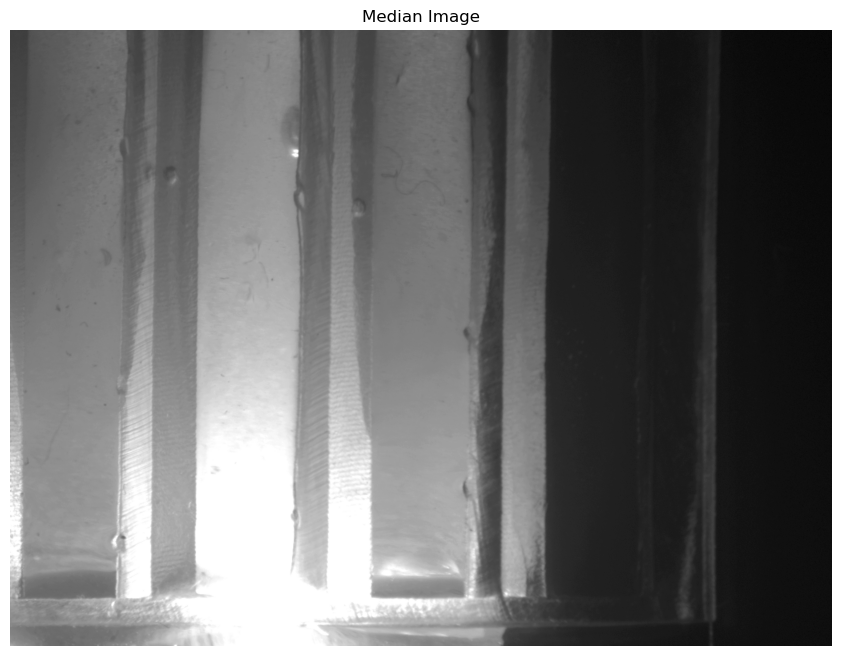

In [5]:
# Compute the median image across all loaded frames
median_frames = np.median(frames_np, axis=0).astype(np.uint8)
print("Median image shape:", median_frames.shape)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(median_frames, cmap='gray')
plt.title('Median Image')
plt.axis('off')
plt.show()

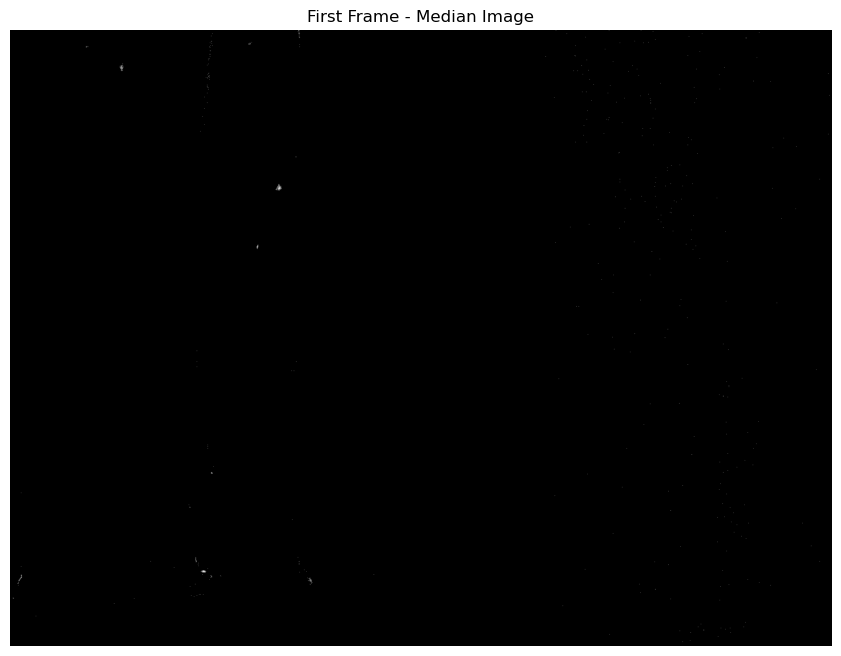

In [49]:
# Subtract the median image from the first frame image
first_frame = frames[0]
diff_img = cv.absdiff(first_frame, median_frames)
diff_img[diff_img < 20] = 0

plt.figure(figsize=(12, 8))
plt.imshow(diff_img*4, cmap='gray')
plt.title('First Frame - Median Image')
plt.axis('off')

plt.show()

In [32]:
output_file = './data/subtracted_video.avi'
fourcc = cv.VideoWriter_fourcc(*'XVID')
out = cv.VideoWriter(output_file, fourcc, metadata['fps'], (width, height), isColor=False)

for frame in frames:
    diff = cv.absdiff(frame, median_frames)
    diff[diff < 10] = 0
    out.write(diff*4)  # Scale for better visibility

out.release()
print(f"Saved subtracted video to {output_file}")

Saved subtracted video to ./data/subtracted_video.avi


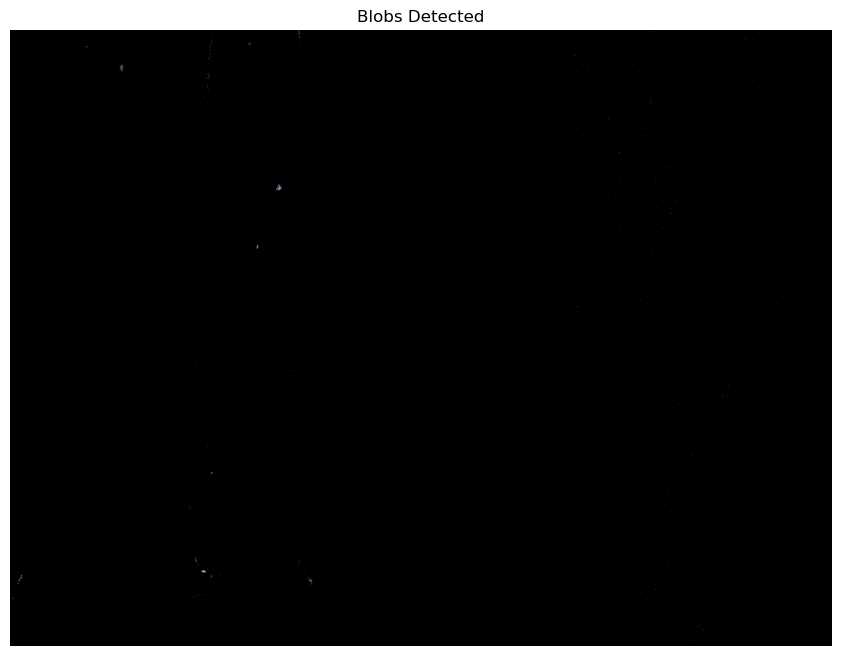

In [50]:
# Identify blobs in the diff_img using OpenCV's SimpleBlobDetector

# Set up the detector with default parameters.
params = cv.SimpleBlobDetector_Params()
params.filterByArea = False
params.minArea = 1
params.maxArea = 50
params.filterByCircularity = False
params.filterByConvexity = False
params.filterByInertia = False

detector = cv.SimpleBlobDetector_create(params)
keypoints = detector.detect(diff_img*4)

# Draw detected blobs as red circles.
im_with_keypoints = cv.drawKeypoints(diff_img*4, keypoints, np.array([]), (0,0,255),
                                     cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(12, 8))
plt.imshow(im_with_keypoints)
plt.title('Blobs Detected')
plt.axis('off')
plt.show()

In [ ]:
coordinates = [(int(k.pt[0]), int(k.pt[1])) for k in keypoints]
coordinates

[(525, 962), (469, 275), (195, 66)]

In [1]:
data_file = './data/whiteLight_aversive.avi'
cap = cv.VideoCapture(data_file)

metadata = {
    'frame_count': int(cap.get(cv.CAP_PROP_FRAME_COUNT)),
    'fps': cap.get(cv.CAP_PROP_FPS),
    'width': int(cap.get(cv.CAP_PROP_FRAME_WIDTH)),
    'height': int(cap.get(cv.CAP_PROP_FRAME_HEIGHT)),
    'fourcc': int(cap.get(cv.CAP_PROP_FOURCC)),
    'convert_rgb': cap.get(cv.CAP_PROP_CONVERT_RGB),
}
print(metadata)


NameError: name 'cv' is not defined